# 7. Business Impact at an Equal Discount Budget

Source of Chapter 7 of the report, the Business Impact slides and the executive brief.
Who should get a 10% retention voucher when the weekly discount budget is fixed? Each
ranking takes customers in its own order until the same **expected discount spend** is
used, and the simulated net margin of its list is compared with sending no offer.

* Test weeks only (Jul-Sep 2011, 10 weekly snapshots), calibrated churn probability `p`
  from `05_scoring.ipynb`, customer value `value_v` (average order value so far, capped at
  the training P99; Section 5.5).
* **Unit of every margin figure:** simulated net margin over the 90 days after one weekly
  list, averaged over the ten weekly cohorts. Cohorts overlap in time, so the figures are
  not added into a yearly profit.
* Selection uses only what is known on the scoring Monday (`p`, `value_v`, recency); the
  realized margin uses the observed churn label.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from policy_lib import expected_margin, row_gain, top_k_mask

BASE = dict(d=.10, e=.30, m=.40, r=.40, c=.50)
K = .20  # reference list: top 20% of each week by expected margin

s = pd.read_parquet("../data/results/churn_scores_h90.parquet")
feat = pd.read_parquet("../data/processed/modeling_dataset_h90.parquet",
                       columns=["customer_id", "snapshot_date", "value_v", "recency_days"])
te = (s[s.split == "test"]
      .merge(feat, on=["customer_id", "snapshot_date"], how="left", validate="one_to_one")
      .reset_index(drop=True))
weeks = te.snapshot_date.nunique()
p = te.churn_probability_calibrated
assert weeks == 10 and te.value_v.notna().all() and te.recency_days.notna().all()
print(f"{len(te):,} rows, {weeks} weekly cohorts, {len(te) / weeks:,.0f} active customers per week; "
      f"mean p {p.mean():.3f} vs churn rate {te.churn.mean():.3f}")

24,252 rows, 10 weekly cohorts, 2,425 active customers per week; mean p 0.418 vs churn rate 0.401


## 7.2 Simulation Method

Contacting a customer with value V either recovers a purchase or subsidises one:

* **would have stopped buying** (churn = 1): a share e come back because of the voucher,
  gain per contact = e·V·(m − d) − c;
* **would have bought anyway** (churn = 0): a share r use the voucher on a purchase they
  would have made, effect per contact = −r·V·d − c.

Before the outcome is known, the expected margin of a contact is
E[ΔM] = p·e·V·(m − d) − (1 − p)·r·V·d − c. Base case: d = 10%, e = 30%, r = 40%,
m = 40%, c = £0.50. All five are assumptions; the data contain no past vouchers or costs.

In [2]:
V = 300
gain_churner = BASE["e"] * V * (BASE["m"] - BASE["d"]) - BASE["c"]
gain_buyer = -BASE["r"] * V * BASE["d"] - BASE["c"]
print(f"V = £{V}: would-be churner {gain_churner:+.2f} per contact, would-be buyer {gain_buyer:+.2f} per contact")

V = £300: would-be churner +26.50 per contact, would-be buyer -12.50 per contact


## 7.3 Weekly Discount Budget

The expected discount cost of one offer is d·V·(p·e + (1 − p)·r): the voucher is used by
the share e of would-be churners and the share r of would-be buyers. The weekly budget is
the expected discount cost of a reference list, the top 20% of each week by expected
margin with E[ΔM] > 0. Every other ranking takes customers in its own order until it
reaches the same budget.

In [3]:
p_ex = 0.6
used = 100 * (p_ex * BASE["e"] + (1 - p_ex) * BASE["r"])
print(f"p = {p_ex}, V = £{V}: {used:.0f} of 100 vouchers used, £{used * V * BASE['d']:,.0f} in total, "
      f"£{used / 100 * V * BASE['d']:.2f} per offer")


def gain(s_):
    return pd.Series(row_gain(te, s_["d"], s_["e"], s_["m"], s_["r"], s_["c"]), index=te.index)


def exp_outlay(s_):
    """Expected discount cost of contacting a customer: d * V * (p*e + (1-p)*r)."""
    return s_["d"] * te.value_v * (p * s_["e"] + (1 - p) * s_["r"])


def real_outlay(s_):
    """Discount given in the simulation, using the observed churn label."""
    return s_["d"] * te.value_v * np.where(te.churn == 1, s_["e"], s_["r"])


def margin_list(s_):
    """Reference list: top K of each week by expected margin, keeping only E[dM] > 0."""
    em = expected_margin(p, te.value_v, s_["d"], s_["e"], s_["m"], s_["r"], s_["c"])
    return top_k_mask(te.assign(em=em), "em", K) & (em > 0)


def fill_budget(score, budget, s_):
    """Per week, take customers by descending score until the expected outlay reaches the budget."""
    out = pd.Series(False, index=te.index)
    eo = exp_outlay(s_)
    for _, g in te.groupby("snapshot_date"):
        order = score[g.index].sort_values(ascending=False).index
        out[order[eo[order].cumsum() <= budget]] = True
    return out


def weekly(mask, s_):
    g = gain(s_)[mask]
    return g.groupby(te.snapshot_date[mask]).sum().reindex(te.snapshot_date.unique(), fill_value=0)


def summarize(mask, s_):
    wk = weekly(mask, s_)
    spend = exp_outlay(s_)[mask].sum() / weeks
    return dict(contacts_week=mask.sum() / weeks, churners_week=te.churn[mask].sum() / weeks,
                expected_spend=spend, discount_given=real_outlay(s_)[mask].sum() / weeks,
                net_margin_90d=wk.mean(), margin_per_gbp_expected=wk.mean() / spend)


def lists(s_):
    """Budget of the reference list and the four lists compared at that budget."""
    ref = margin_list(s_)
    budget = exp_outlay(s_)[ref].sum() / weeks
    rand = pd.Series(np.random.default_rng(0).uniform(size=len(te)), index=te.index)
    return budget, {
        "Highest risk of no purchase": fill_budget(p, budget, s_),
        "Highest expected margin per contact": ref,
        "Longest time since last purchase": fill_budget(te.recency_days, budget, s_),
        "Random (reference)": fill_budget(rand, budget, s_),
    }

p = 0.6, V = £300: 34 of 100 vouchers used, £1,020 in total, £10.20 per offer


## 7.4 Results at Equal Budget (Base scenario)

`expected_spend` is what each list is expected to cost when it is chosen, and is equal
across lists by construction. `discount_given` is the discount the simulation actually
hands out once the observed labels are known.

In [4]:
B, masks = lists(BASE)
res = pd.DataFrame({k: summarize(v, BASE) for k, v in masks.items()}).T
res.to_csv("../data/results/budget_comparison.csv")
print(f"Weekly expected discount budget: £{B:,.0f}")
res.round(2)

Weekly expected discount budget: £8,219


,contacts_week,churners_week,expected_spend,discount_given,net_margin_90d,margin_per_gbp_expected
Highest risk of no purchase,826.1,521.2,8213.18,8357.24,9060.37,1.10
Highest expected margin per contact,485.0,287.6,8219.39,8315.64,8227.50,1.00
Longest time since last purchase,684.4,378.1,8209.90,8319.60,6078.56,0.74
Random (reference),604.6,241.0,8200.55,8238.26,979.06,0.12


In [5]:
RISK, REF, REC = "Highest risk of no purchase", "Highest expected margin per contact", "Longest time since last purchase"
wk = {n: weekly(m, BASE) for n, m in masks.items()}
risk, ref, rec = res.loc[RISK], res.loc[REF], res.loc[REC]
print(f"Risk ranking vs longest since purchase: +£{risk.net_margin_90d - rec.net_margin_90d:,.0f} "
      f"({risk.net_margin_90d / rec.net_margin_90d - 1:+.0%}), ahead in {(wk[RISK] > wk[REC]).sum()} of {weeks} weeks")
print(f"Risk ranking vs expected-margin list: ahead in {(wk[RISK] > wk[REF]).sum()} of {weeks} weeks; the expected-margin "
      f"list uses {risk.contacts_week - ref.contacts_week:,.0f} fewer contacts and gives up "
      f"£{risk.net_margin_90d - ref.net_margin_90d:,.0f} of margin")
print(f"Risk ranking: £{risk.margin_per_gbp_expected:.2f} of margin per £1 of expected discount, "
      f"£{risk.net_margin_90d / risk.discount_given:.2f} per £1 of discount given; "
      f"{risk.contacts_week / (len(te) / weeks):.0%} of active customers contacted")

Risk ranking vs longest since purchase: +£2,982 (+49%), ahead in 10 of 10 weeks
Risk ranking vs expected-margin list: ahead in 10 of 10 weeks; the expected-margin list uses 341 fewer contacts and gives up £833 of margin
Risk ranking: £1.10 of margin per £1 of expected discount, £1.08 per £1 of discount given; 34% of active customers contacted


In [6]:
# Ranking quality of the orderings on the test weeks (pooled AUC for the observed churn label)
from sklearn.metrics import roc_auc_score
auc = pd.Series({
    "Calibrated churn probability (final model)": roc_auc_score(te.churn, p),
    "Days since last purchase (recency rule)": roc_auc_score(te.churn, te.recency_days),
    "Random": roc_auc_score(te.churn, np.random.default_rng(0).uniform(size=len(te))),
}, name="test AUC")
auc.round(3)

Calibrated churn probability (final model)    0.759
Days since last purchase (recency rule)       0.638
Random                                        0.496
Name: test AUC, dtype: float64

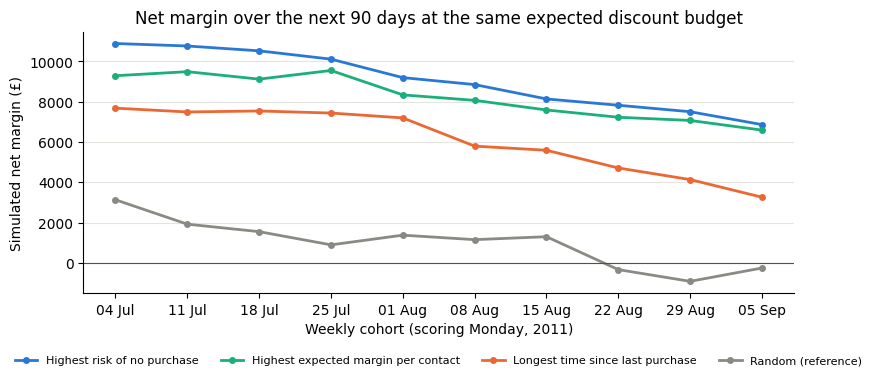

In [7]:
colors = {RISK: "#2a78d6", REF: "#1baf7a", REC: "#eb6834", "Random (reference)": "#8a8a85"}
fig, ax = plt.subplots(figsize=(9, 4))
for n, w in wk.items():
    ax.plot(w.index, w.values, marker="o", lw=2, ms=4, color=colors[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8)
weeks_index = sorted(te.snapshot_date.unique())
ax.set_xticks(weeks_index)
ax.set_xticklabels([pd.Timestamp(d).strftime("%d %b") for d in weeks_index])
ax.set_ylabel("Simulated net margin (£)")
ax.set_xlabel("Weekly cohort (scoring Monday, 2011)")
ax.set_title("Net margin over the next 90 days at the same expected discount budget")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e0")
fig.tight_layout()
fig.savefig("../report/figures/ch7_equal_budget_weekly.png", dpi=150, bbox_inches="tight")
plt.show()

## 7.5 Scenario Analysis

**Voucher depth.** Light (5% voucher, e = 20%), Base (10%, 30%) and Deep (20%, 40%). The
budget is recomputed in each scenario from that scenario's reference list.

In [8]:
rows = []
for name, (d, e) in {"Light": (.05, .20), "Base": (.10, .30), "Deep": (.20, .40)}.items():
    s_ = {**BASE, "d": d, "e": e}
    B_s, m_s = lists(s_)
    w = {n: weekly(m, s_) for n, m in m_s.items()}
    rows.append(dict(scenario=name, voucher=d, response=e, budget=B_s,
                     risk_contacts=m_s[RISK].sum() / weeks, risk=w[RISK].mean(),
                     expected_margin_list=w[REF].mean(), longest_since_purchase=w[REC].mean(),
                     risk_ahead_of_recency_weeks=int((w[RISK] > w[REC]).sum()),
                     risk_ahead_of_margin_list_weeks=int((w[RISK] > w[REF]).sum())))
scen = pd.DataFrame(rows).set_index("scenario")
scen.to_csv("../data/results/equal_budget_scenarios.csv")
scen.round(2)

,voucher,response,budget,risk_contacts,risk,expected_margin_list,longest_since_purchase,risk_ahead_of_recency_weeks,risk_ahead_of_margin_list_weeks
scenario,,,,,,,,,
Light,0.05,0.2,3724.52,906.2,8754.18,7766.21,6223.65,10,10
Base,0.10,0.3,8219.39,826.1,9060.37,8227.50,6078.56,10,10
Deep,0.20,0.4,14866.19,664.1,3695.45,3173.07,664.17,10,9


**Gross margin.** The data hold revenue only, so m is an assumption that Finance should
confirm. Base voucher, m = 30%, 40% and 50%, each at its own equal budget.

In [9]:
rows = []
for m_ in (.30, .40, .50):
    s_ = {**BASE, "m": m_}
    B_s, m_s = lists(s_)
    w = {n: weekly(mk, s_) for n, mk in m_s.items()}
    rows.append(dict(gross_margin=m_, budget=B_s, risk_contacts=m_s[RISK].sum() / weeks, risk=w[RISK].mean(),
                     expected_margin_list=w[REF].mean(), longest_since_purchase=w[REC].mean(),
                     risk_ahead_of_recency_weeks=int((w[RISK] > w[REC]).sum())))
sens = pd.DataFrame(rows).set_index("gross_margin")
sens.to_csv("../data/results/margin_sensitivity.csv")
sens.round(2)

,budget,risk_contacts,risk,expected_margin_list,longest_since_purchase,risk_ahead_of_recency_weeks
gross_margin,,,,,,
0.3,7294.16,755.3,4368.89,3989.31,2291.20,10
0.4,8219.39,826.1,9060.37,8227.50,6078.56,10
0.5,8744.36,867.1,14132.11,12670.01,10102.99,10
